# 单翼羽化限位修正：±26.1°

用户明确纠正实际羽化限位为 ±26.1°。此前 ±50° 的记录是错误限位下的历史结果，不应继续用于实物验证。
MJCF 与 URDF 左右羽化关节均已改为 ±0.455530934771 rad；未增加羽化驱动或弹簧。

单翼装配仍为保留两侧扑翼传动、拆除右翼板。每组运行 2 s，步长 5 µs，采样 2 kHz。
前 0.6 s 排除，对完整输出轴周期积分；实际频率误差小于 0.01 Hz。
主扫描仅修正限位，保留原来的矩形条带气动参数，保证能单独观察角度设置的影响。

| Hz | 实际 Hz | ±26.1° Fz/mN | 历史 ±50° Fz/mN | 实测基线校正估计/mN |
|---:|---:|---:|---:|---:|
| 10 | 9.99988 | 21.97 | 21.51 | 15.22 |
| 11 | 10.99983 | 26.45 | 25.98 | 17.00 |
| 12 | 11.99976 | 31.33 | 30.74 | 19.56 |
| 13 | 12.99968 | 36.59 | 35.95 | 22.87 |
| 14 | 13.99959 | 42.26 | 41.54 | 26.29 |
| 15 | 14.99947 | 48.08 | 47.57 | 29.85 |



## CAD 几何端点复查

为了复查上一次几何归因，又对 CAD 条带面积、作用点、旋转阻尼诊断模型应用了 ±26.1° 限位。
该诊断没有根据实测力拟合系数：

- 10 Hz：实际 9.99452 Hz，平均 Fz 12.345 mN。
- 15 Hz：实际 14.99998 Hz，平均 Fz 27.473 mN。

上一轮“CAD 几何诊断的 15 Hz 与实测接近”是在错误的 ±50° 限位下得到的，不能继续据此认定模型已准确或几何是唯一主因。
矩形轮廓与真实 CAD 不匹配这个代码事实仍然成立，但必须在正确限位下联合验证几何和羽化响应。
真实数据仍沿用先前运行减末段基线的估计；静止清零、Fz 正向和末段状态尚需确认。
本次不调整原始实测数据，不调整经验气动系数来贴合结果。

## 复现与文件

运行 `python experiments/fixbase/rerun_26p1deg.py`。
新扫描保存于 `results_single_wing_26p1deg_10_15hz/`，旧 ±50° 记录保留。
每个频率子目录包含调速记录、CSV/NPZ、六维载荷图与关节运动图；`model/` 保存本次模型副本。
CAD 端点诊断保存于 `experiments/fixbase_curved_real/analysis/geometry_sensitivity_26p1deg/`。


通过：六组真实记录、±26.1° 限位、实际频率及完整周期升力复核。


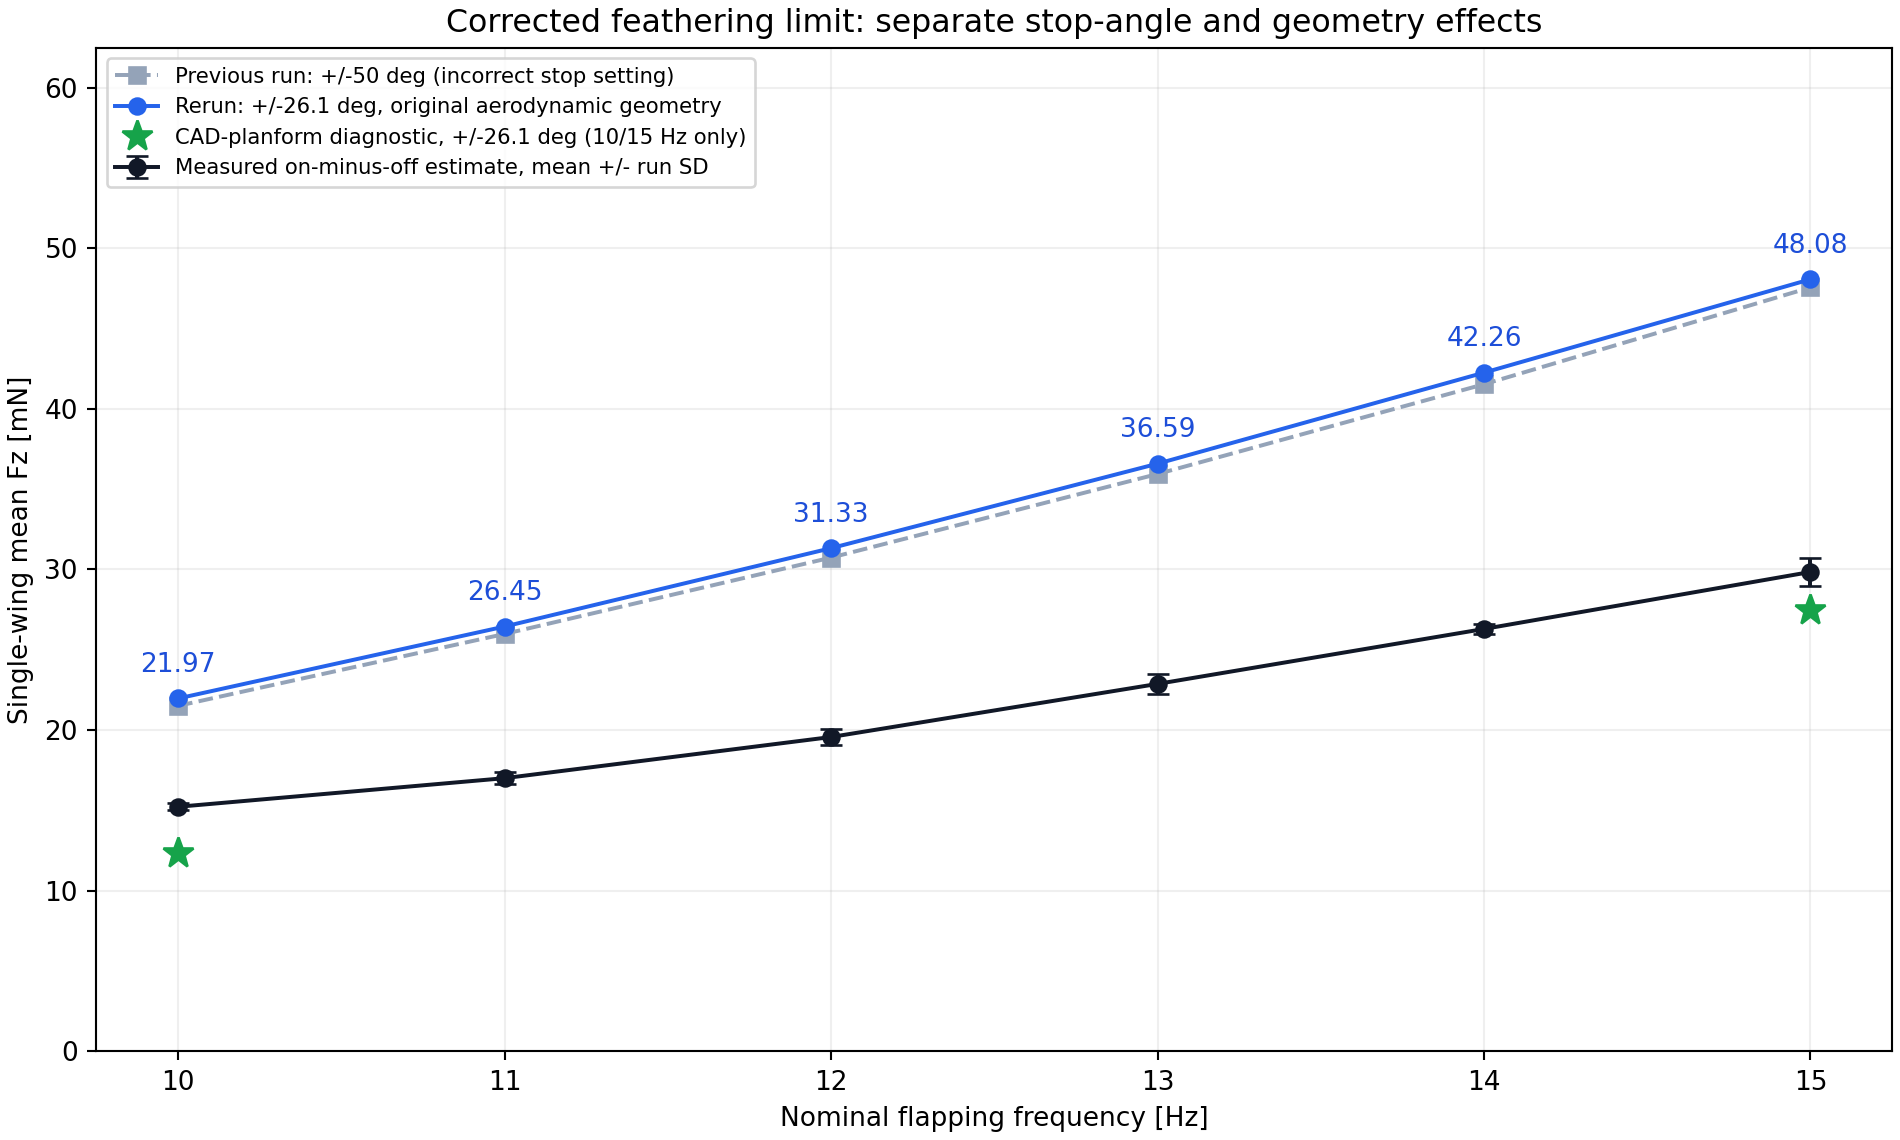

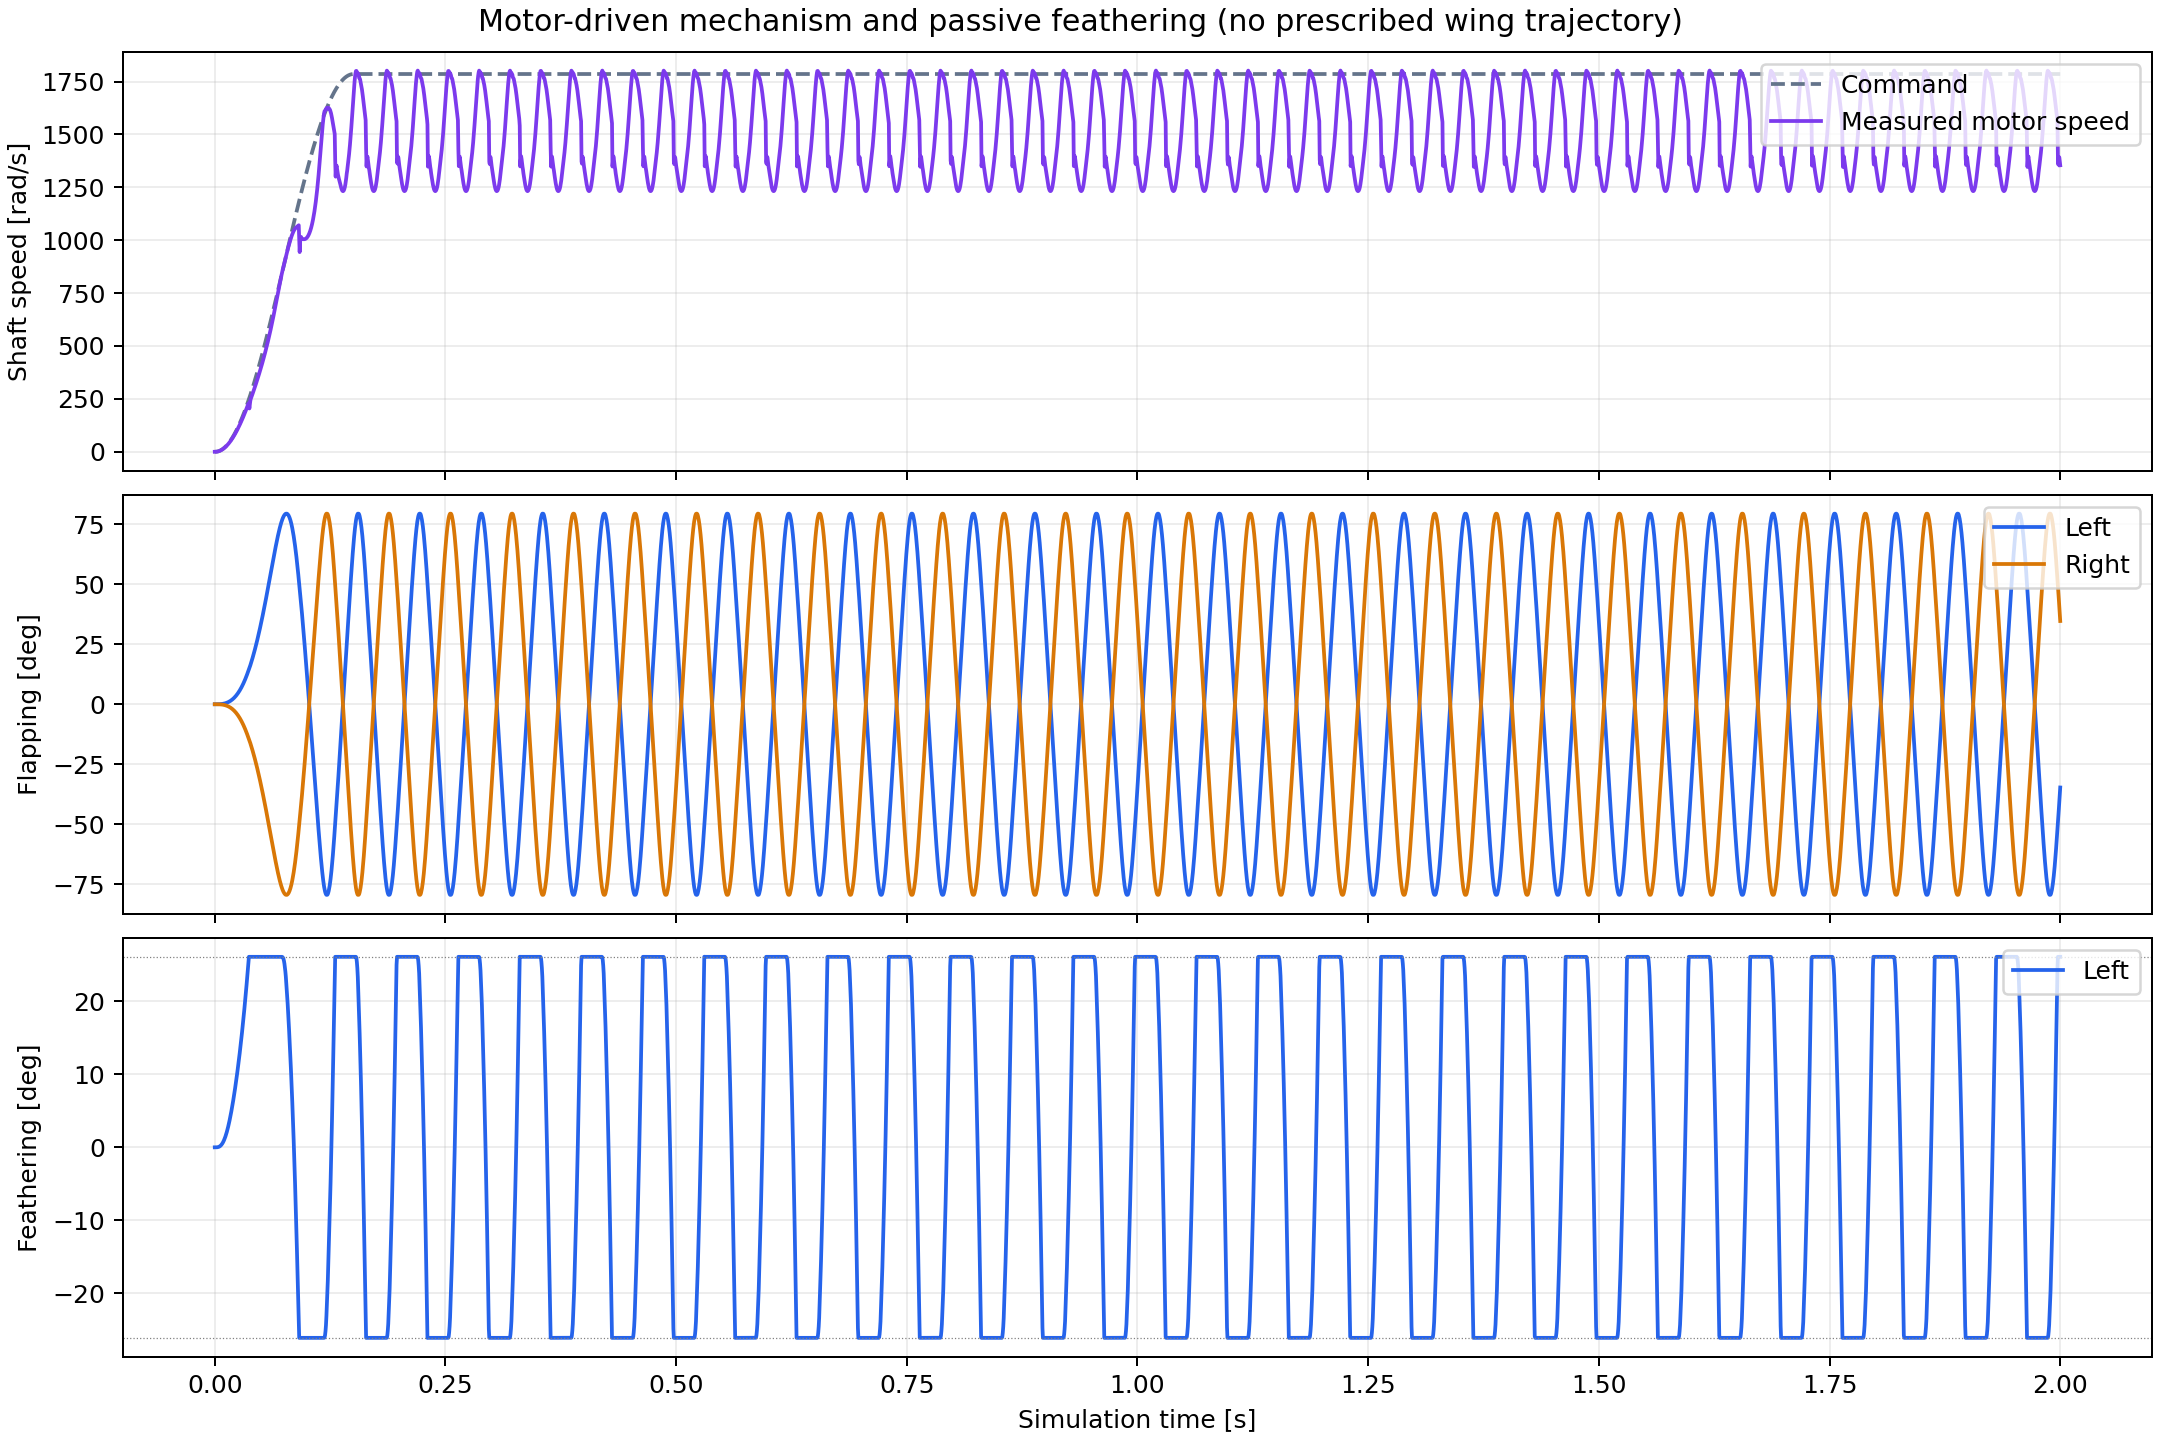

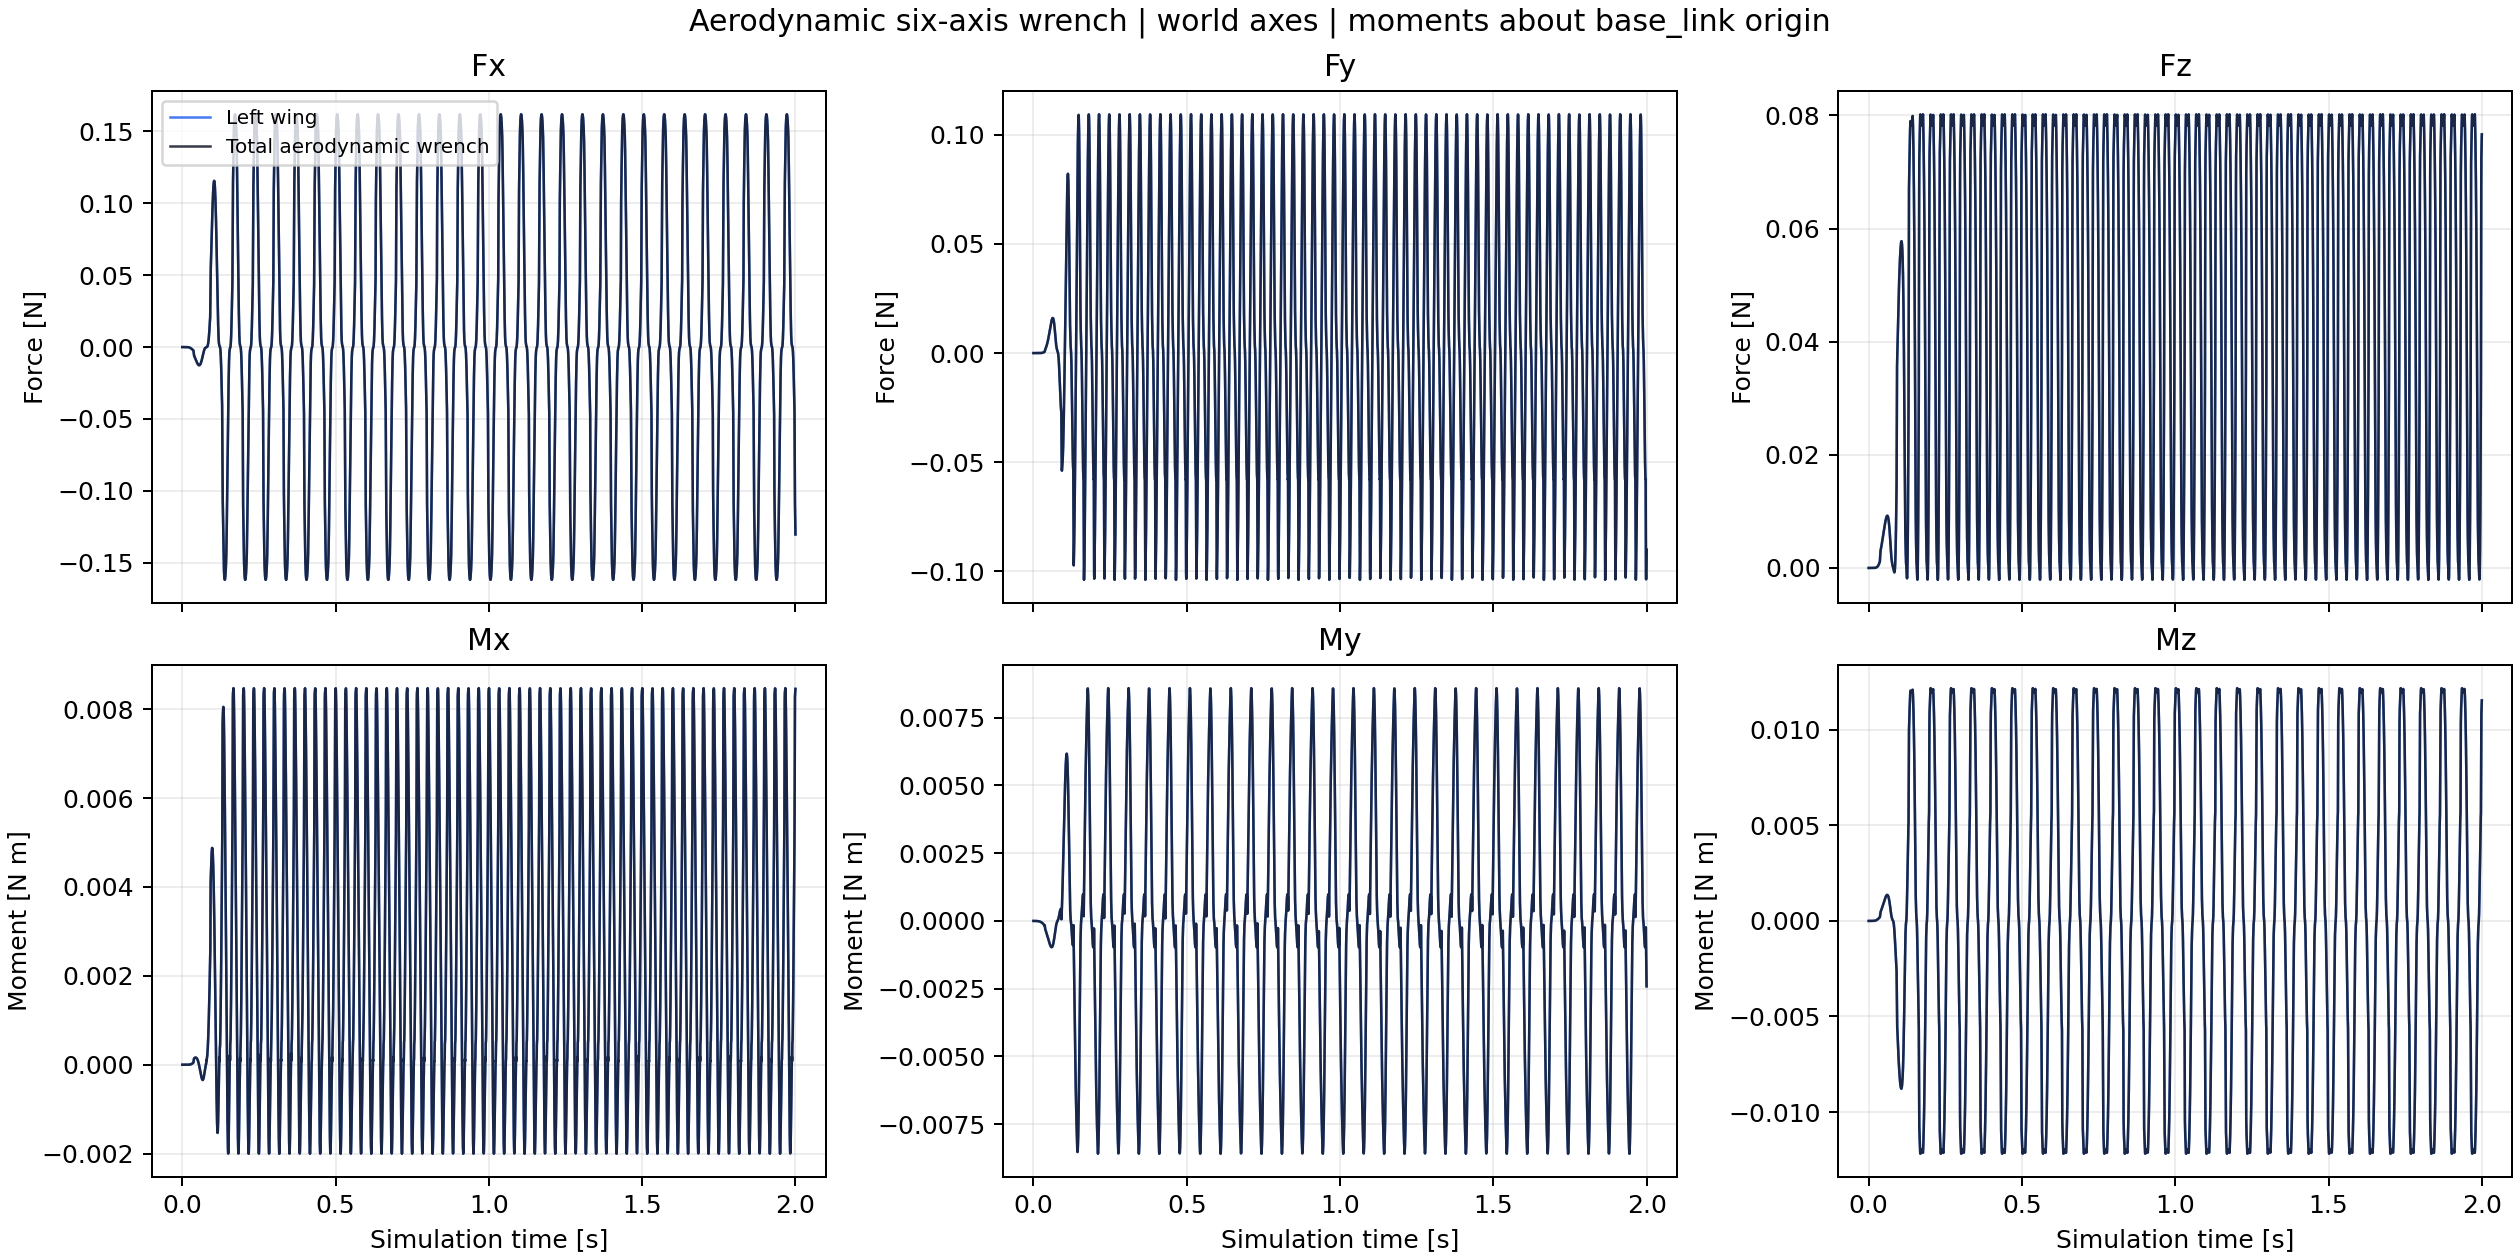

In [1]:
from pathlib import Path
import sys,json
import numpy as np
from IPython.display import display,Image
FOLDER=Path.cwd().resolve()
sys.path.insert(0,str(FOLDER))
from rerun_26p1deg import OUTPUT
from single_wing_sweep import single_config
from sweep_frequency import saved_run
from run_15hz import cycle_statistics
config=single_config(OUTPUT/'model/IST_robot_single_left_wing.xml')
results=json.loads((OUTPUT/'sweep.json').read_text())
assert len(results)==6
for r in results:
    d,s=saved_run(FOLDER/r['source_folder'],config)
    np.testing.assert_allclose(s['pitch_limits_deg']['left_feathering_joint'],[-26.1,26.1],atol=1e-8)
    assert np.max(np.abs(np.degrees(d['left_feathering_joint_angle_rad'])))<26.2
    assert abs(r['measured_wing_frequency_hz']-r['target_wing_frequency_hz'])<.01
    np.testing.assert_allclose(cycle_statistics(d)['mean_lift_N'],r['mean_lift_N'],atol=1e-12)
print('通过：六组真实记录、±26.1° 限位、实际频率及完整周期升力复核。')
display(Image(filename=str(OUTPUT/'comparison_26p1deg.png')))
display(Image(filename=str(OUTPUT/'15hz/joint_motion.png')))
display(Image(filename=str(OUTPUT/'15hz/wrench_6d.png')))